In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from keras import layers, models
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import pickle

2025-06-10 15:24:39.716950: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-06-10 15:24:39.753590: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-06-10 15:24:39.802883: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-06-10 15:24:39.837521: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-06-10 15:24:39.848905: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-06-10 15:24:39.919793: I tensorflow/core/platform/cpu_feature_gu

In [2]:
tf.config.run_functions_eagerly(True)

tf.keras.utils.get_file(
  "bike_sharing_dataset.zip",
  "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip",
  cache_dir=".",
  extract=True
)

try:
  import shutil
  src = 'datasets/bike_sharing_dataset_extracted/hour.csv'
  dst = 'datasets/hour.csv'
  shutil.copy(src, dst)
  src = 'datasets/bike_sharing_dataset_extracted/day.csv'
  dst = 'datasets/day.csv'
  shutil.copy(src, dst)
except Exception as e:
  print(e)

In [3]:
df = pd.read_csv('datasets/bike_sharing_dataset_extracted/hour.csv')
df['datetime'] = pd.to_datetime(df['dteday'] + ' ' + df['hr'].astype(str).str.zfill(2), format='%Y-%m-%d %H')
df.set_index('datetime', inplace=True)
df

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
datetime,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
2011-01-01 01:00:00,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2011-01-01 02:00:00,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
2011-01-01 03:00:00,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
2011-01-01 04:00:00,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2012-12-31 19:00:00,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
2012-12-31 20:00:00,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
2012-12-31 21:00:00,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90


In [4]:
print((df.index.min(), df.index.max()))

(Timestamp('2011-01-01 00:00:00'), Timestamp('2012-12-31 23:00:00'))


In [5]:
(365 + 366) * 24 - len(df)

165

In [6]:
df_rent_count = df[['casual', 'registered', 'cnt']].resample('h').asfreq().fillna(0)
df_sensor = df[['temp', 'atemp', 'hum', 'windspeed']].resample('h').interpolate()
df_categorical = df[['holiday', 'weekday', 'workingday', 'weathersit']].resample('h').ffill()

df = pd.concat([df_rent_count, df_sensor, df_categorical], axis=1)
df.notna().sum()

casual        17544
registered    17544
cnt           17544
temp          17544
atemp         17544
hum           17544
windspeed     17544
holiday       17544
weekday       17544
workingday    17544
weathersit    17544
dtype: int64

In [7]:
df[['casual', 'registered', 'cnt', 'weathersit']].describe()

,casual,registered,cnt,weathersit
count,17544.000000,17544.000000,17544.000000,17544.000000
mean,35.340686,152.340515,187.681202,1.434223
std,49.193293,151.373409,181.456478,0.648339
min,0.000000,0.000000,0.000000,1.000000
25%,4.000000,32.000000,38.000000,1.000000
50%,16.000000,114.000000,140.000000,1.000000
75%,48.000000,219.000000,279.000000,2.000000
max,367.000000,886.000000,977.000000,4.000000


<Axes: xlabel='datetime'>

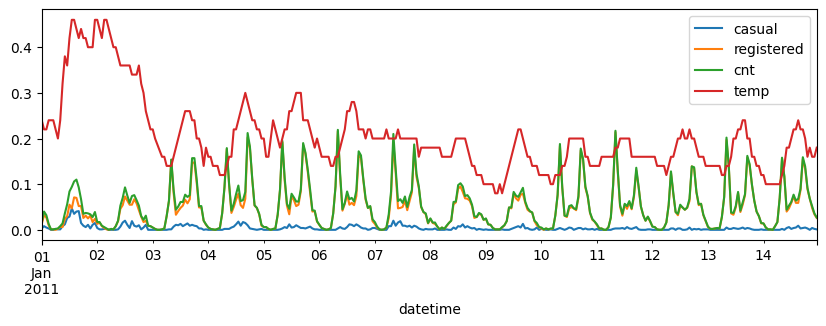

In [8]:
df.casual /= 1e3
df.registered /= 1e3
df.cnt /= 1e3
df.weathersit /= 4

df_2weeks = df[:24 * 7 * 2]
df_2weeks[['casual', 'registered', 'cnt', 'temp']].plot(figsize=(10, 3))

<Axes: xlabel='datetime'>

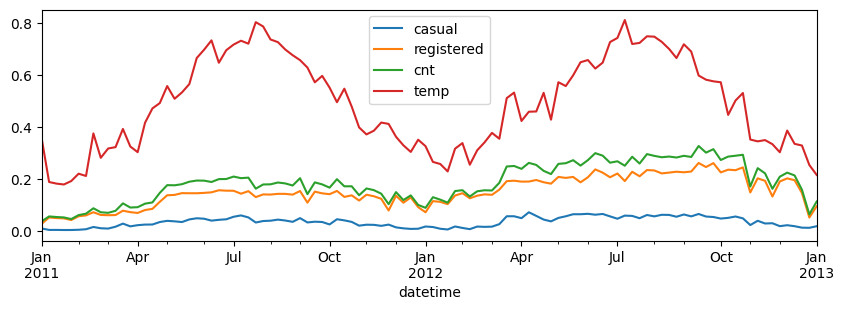

In [9]:
df_daily = df.resample('W').mean()
df_daily[['casual', 'registered', 'cnt', 'temp']].plot(figsize=(10, 3))

In [10]:
# Naive indicators

cnt = df['cnt'] * 1e3

mae_daily = mean_absolute_error(cnt[24:], cnt.shift(24)[24:])
mae_weekly = mean_absolute_error(cnt[168:], cnt.shift(168)[168:])

# Zaokrąglamy do 2 miejsc po przecinku
mae_baseline = (mae_daily, mae_weekly)

# Zapisujemy do pliku
with open("mae_baseline.pkl", "wb") as f:
    pickle.dump(mae_baseline, f)

mae_baseline

(63.79497716894977, 52.42506906077348)

In [11]:
# Dense Network Prediction

cnt_train = df['cnt']['2011-01-01 00:00':'2012-06-30 23:00']
cnt_valid = df['cnt']['2012-07-01 00:00':]

seq_len = 1 * 24
train_ds = tf.keras.utils.timeseries_dataset_from_array(
    cnt_train.to_numpy(),
    targets=cnt_train[seq_len:],
    sequence_length=seq_len,
    batch_size=32,
    shuffle=True,
    seed=42
)
valid_ds = tf.keras.utils.timeseries_dataset_from_array(
    cnt_valid.to_numpy(),
    targets=cnt_valid[seq_len:],
    sequence_length=seq_len,
    batch_size=32
)

I0000 00:00:1749561884.359908    2939 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2025-06-10 15:24:44.360434: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2343] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
/home/piotrp/miniconda3/envs/ml/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


In [12]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(seq_len,)),
    tf.keras.layers.Dense(1)
])

optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model.compile(loss="huber", optimizer=optimizer, metrics=['mae'])

In [13]:
history = model.fit(train_ds, validation_data=valid_ds, epochs=20)
model.save('model_linear.keras')

Epoch 1/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0155 - mae: 0.1237 - val_loss: 0.0059 - val_mae: 0.0793
Epoch 2/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.0026 - mae: 0.0519 - val_loss: 0.0045 - val_mae: 0.0673
Epoch 3/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.0022 - mae: 0.0462 - val_loss: 0.0041 - val_mae: 0.0640
Epoch 4/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.0020 - mae: 0.0446 - val_loss: 0.0039 - val_mae: 0.0623
Epoch 5/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.0020 - mae: 0.0435 - val_loss: 0.0038 - val_mae: 0.0611
Epoch 6/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.0019 - mae: 0.0429 - val_loss: 0.0037 - val_mae: 0.0602
Epoch 7/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.0019 - mae: 0.0422 - val_loss: 0.0037 - val_mae: 0.0596
Epoch 8/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0019 - mae: 0.0418 - val_loss: 0.0036 - val_mae: 0.0588
Epoch 9/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/

In [14]:
loss, mae_linear = model.evaluate(valid_ds)
mae_linear *= 1e3

with open('mae_linear.pkl', 'wb') as f:
    pickle.dump((mae_linear,), f)

mae_linear

138/138 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0036 - mae: 0.0589 


55.883292108774185

In [15]:
# Simple RNN Prediction

model = tf.keras.Sequential([
    tf.keras.Input(shape=[None, 1]),
    tf.keras.layers.LSTM(1)
])

optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model.compile(loss="huber", optimizer=optimizer, metrics=['mae'])

In [16]:
history = model.fit(train_ds, validation_data=valid_ds, epochs=20)
model.save('model_rnn1.keras')

Epoch 1/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 36s 86ms/step - loss: 0.0252 - mae: 0.1743 - val_loss: 0.0250 - val_mae: 0.1692
Epoch 2/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 37s 91ms/step - loss: 0.0115 - mae: 0.1215 - val_loss: 0.0201 - val_mae: 0.1506
Epoch 3/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 35s 86ms/step - loss: 0.0097 - mae: 0.1097 - val_loss: 0.0185 - val_mae: 0.1444
Epoch 4/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 36s 88ms/step - loss: 0.0089 - mae: 0.1032 - val_loss: 0.0175 - val_mae: 0.1408
Epoch 5/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 35s 86ms/step - loss: 0.0083 - mae: 0.0990 - val_loss: 0.0169 - val_mae: 0.1374
Epoch 6/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 36s 87ms/step - loss: 0.0080 - mae: 0.0960 - val_loss: 0.0162 - val_mae: 0.1344
Epoch 7/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 35s 87ms/step - loss: 0.0077 - mae: 0.0938 - val_loss: 0.0156 - val_mae: 0.1311
Epoch 8/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 36s 88ms/step - loss: 0.0074 - mae: 0.0917 - val_loss: 0.0151 - val_mae: 0.1280
Epoch 9/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 

In [18]:
loss, mae_rnn1 = model.evaluate(valid_ds)
mae_rnn1 *= 1e3

with open('mae_rnn1.pkl', 'wb') as f:
    pickle.dump((mae_rnn1,), f)

mae_rnn1

138/138 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - loss: 0.0119 - mae: 0.1108


104.48874533176422

In [29]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=[None, 1]),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(1)
])

optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model.compile(loss="huber", optimizer=optimizer, metrics=['mae'])

In [30]:
history = model.fit(train_ds, validation_data=valid_ds, epochs=20)
model.save('model_rnn32.keras')

Epoch 1/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 38s 94ms/step - loss: 0.0146 - mae: 0.1312 - val_loss: 0.0179 - val_mae: 0.1355
Epoch 2/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 38s 92ms/step - loss: 0.0081 - mae: 0.0961 - val_loss: 0.0154 - val_mae: 0.1198
Epoch 3/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 36s 87ms/step - loss: 0.0070 - mae: 0.0869 - val_loss: 0.0145 - val_mae: 0.1092
Epoch 4/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 36s 87ms/step - loss: 0.0063 - mae: 0.0810 - val_loss: 0.0127 - val_mae: 0.1036
Epoch 5/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 36s 88ms/step - loss: 0.0059 - mae: 0.0775 - val_loss: 0.0120 - val_mae: 0.1004
Epoch 6/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 36s 87ms/step - loss: 0.0057 - mae: 0.0748 - val_loss: 0.0123 - val_mae: 0.0999
Epoch 7/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 36s 87ms/step - loss: 0.0054 - mae: 0.0722 - val_loss: 0.0113 - val_mae: 0.0970
Epoch 8/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 36s 88ms/step - loss: 0.0052 - mae: 0.0705 - val_loss: 0.0113 - val_mae: 0.0964
Epoch 9/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 

In [32]:
loss, mae_rnn2 = model.evaluate(valid_ds)
mae_rnn2 *= 1e3

with open('mae_rnn32.pkl', 'wb') as f:
    pickle.dump((mae_rnn2,), f)

mae_rnn2

138/138 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - loss: 0.0101 - mae: 0.0936


87.89025992155075

In [43]:
# Deep RNN Prediction

model = tf.keras.Sequential([
    tf.keras.Input(shape=[None, 1]),
    tf.keras.layers.LSTM(32, return_sequences=True),
    tf.keras.layers.LSTM(32, return_sequences=True),
    tf.keras.layers.LSTM(32, return_sequences=False),
    tf.keras.layers.Dense(1)
])

optimizer = tf.keras.optimizers.SGD(learning_rate=0.05, momentum=0.9)
model.compile(loss="huber", optimizer=optimizer, metrics=['mae'])

In [44]:
history = model.fit(train_ds, validation_data=valid_ds, epochs=20)
model.save('model_rnn_deep.keras')

Epoch 1/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 106s 258ms/step - loss: 0.0146 - mae: 0.1336 - val_loss: 0.0269 - val_mae: 0.1760
Epoch 2/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 109s 266ms/step - loss: 0.0130 - mae: 0.1265 - val_loss: 0.0235 - val_mae: 0.1603
Epoch 3/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 111s 270ms/step - loss: 0.0096 - mae: 0.1048 - val_loss: 0.0149 - val_mae: 0.1172
Epoch 4/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 109s 266ms/step - loss: 0.0067 - mae: 0.0848 - val_loss: 0.0124 - val_mae: 0.1129
Epoch 5/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 106s 259ms/step - loss: 0.0062 - mae: 0.0811 - val_loss: 0.0119 - val_mae: 0.1132
Epoch 6/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 105s 257ms/step - loss: 0.0063 - mae: 0.0816 - val_loss: 0.0123 - val_mae: 0.1100
Epoch 7/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 106s 257ms/step - loss: 0.0065 - mae: 0.0833 - val_loss: 0.0113 - val_mae: 0.1098
Epoch 8/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 106s 258ms/step - loss: 0.0059 - mae: 0.0783 - val_loss: 0.0115 - val_mae: 0.1113
Epoch 9/20
410/410 ━━━━━

In [45]:
loss, mae_rnn_deep = model.evaluate(valid_ds)
mae_rnn_deep *= 1e3

with open('mae_rnn_deep.pkl', 'wb') as f:
    pickle.dump((mae_rnn_deep,), f)

mae_rnn_deep

138/138 ━━━━━━━━━━━━━━━━━━━━ 16s 114ms/step - loss: 0.0079 - mae: 0.0874


79.96395975351334

In [46]:
# Multivariate Prediction Model

input_columns = ['cnt', 'atemp', 'weathersit', 'workingday']
df_multi = df[input_columns]

X_train_df = df_multi['2011-01-01 00:00':'2012-06-30 23:00']
X_valid_df = df_multi['2012-07-01 00:00':]

X_train_arr = X_train_df.to_numpy()
X_valid_arr = X_valid_df.to_numpy()

seq_len = 1 * 24

train_ds = tf.keras.utils.timeseries_dataset_from_array(
    data=X_train_arr,
    targets=X_train_arr[seq_len:, 0],
    sequence_length=seq_len,
    batch_size=32,
    shuffle=True,
    seed=123
)

valid_ds = tf.keras.utils.timeseries_dataset_from_array(
    data=X_valid_arr,
    targets=X_valid_arr[seq_len:, 0],
    sequence_length=seq_len,
    batch_size=32
)

/home/piotrp/miniconda3/envs/ml/lib/python3.11/site-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


In [47]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(seq_len, len(input_columns))),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(1)
])

optimizer = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
model.compile(loss="huber", optimizer=optimizer, metrics=['mae'])

In [48]:
history = model.fit(train_ds, validation_data=valid_ds, epochs=20)
model.save('model_rnn_mv.keras')

Epoch 1/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 38s 92ms/step - loss: 0.0116 - mae: 0.1158 - val_loss: 0.0176 - val_mae: 0.1376
Epoch 2/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 38s 93ms/step - loss: 0.0081 - mae: 0.0954 - val_loss: 0.0158 - val_mae: 0.1258
Epoch 3/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 38s 93ms/step - loss: 0.0072 - mae: 0.0887 - val_loss: 0.0139 - val_mae: 0.1174
Epoch 4/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 38s 92ms/step - loss: 0.0064 - mae: 0.0830 - val_loss: 0.0129 - val_mae: 0.1084
Epoch 5/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 38s 92ms/step - loss: 0.0058 - mae: 0.0782 - val_loss: 0.0117 - val_mae: 0.1020
Epoch 6/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 38s 93ms/step - loss: 0.0054 - mae: 0.0742 - val_loss: 0.0116 - val_mae: 0.0957
Epoch 7/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 38s 93ms/step - loss: 0.0051 - mae: 0.0713 - val_loss: 0.0103 - val_mae: 0.0925
Epoch 8/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 38s 92ms/step - loss: 0.0048 - mae: 0.0689 - val_loss: 0.0107 - val_mae: 0.0916
Epoch 9/20
410/410 ━━━━━━━━━━━━━━━━━━━━ 

In [49]:
loss, mae_rnn_mv = model.evaluate(valid_ds)
mae_rnn_mv *= 1e3

with open('mae_rnn_mv.pkl', 'wb') as f:
    pickle.dump((mae_rnn_mv,), f)

mae_rnn_mv

138/138 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - loss: 0.0087 - mae: 0.0858


81.76077157258987